<a href="https://colab.research.google.com/github/hbhoomikacs24-stack/bio_inspired_lab/blob/main/week5_paralell_water_tank_application_1BM24CS107.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

✅ PARALLEL CELLULAR ALGORITHM OPTIMIZATION COMPLETE
Total Grid System Fitness : 29611.91
Total Daily Energy Cost   : ₹1605.00 across 9 Tanks

Cell (Tank) | Init Lvl | Final Lvl | Min Lvl | Max Lvl | Pump Hrs | Energy Cost
------------------------------------------------------------------------------
 Tank (0,0)  |    5311L |     3503L |   3503L |   9777L |    9 hrs |   ₹200.00
 Tank (0,1)  |    7328L |     3615L |   3615L |   9731L |    6 hrs |   ₹132.50
 Tank (0,2)  |    6562L |     3422L |   3422L |   8754L |    9 hrs |   ₹185.00
 Tank (1,0)  |    6095L |    12655L |   6095L |  13040L |   14 hrs |   ₹280.00
 Tank (1,1)  |    4546L |     3459L |   2783L |   6803L |    8 hrs |   ₹177.50
 Tank (1,2)  |    4546L |     5414L |   4175L |   9901L |    9 hrs |   ₹195.00
 Tank (2,0)  |    4203L |     3263L |   2730L |   7079L |    8 hrs |   ₹152.50
 Tank (2,1)  |    7032L |     3677L |   3195L |   9879L |    7 hrs |   ₹132.50
 Tank (2,2)  |    6104L |     3428L |   3038L |   8898L |    8 hrs 

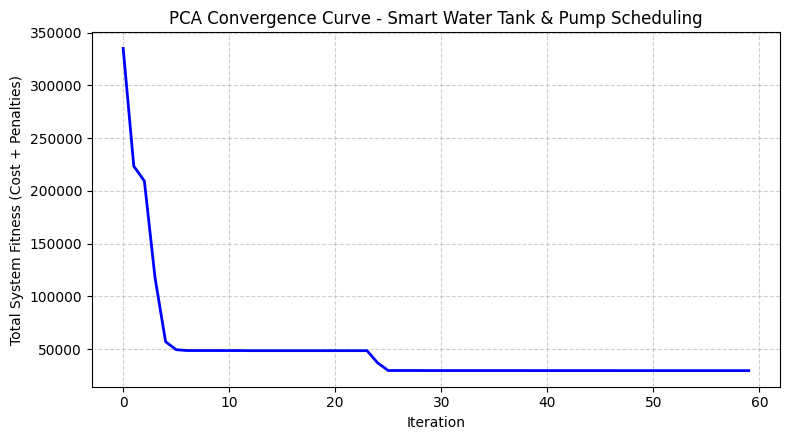

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor

# ==========================================
# OBJECTIVE 1: REPRESENT TANKS & DISTRIBUTION POINTS AS CELLS
# ==========================================
ROWS, COLS = 3, 3        # 3x3 Grid = 9 Interconnected Water Tanks / Distribution Zones
HOURS = 24               # 24-Hour Scheduling Horizon
MAX_ITER = 60            # Optimization Iterations
ALPHA = 0.5              # Neighbor learning rate

# Tank Specifications
TANK_MAX = 10000.0       # Max tank capacity (Liters)
TANK_MIN = 2000.0        # Minimum safe reserve (Liters)
PUMP_RATE = 1800.0       # Liters pumped per hour when pump is ON
PUMP_POWER_KW = 2.5      # Pump power rating (kW)

# Hourly Electricity Tariff (₹ per kWh - Peak hours cost more)
tariff = np.array([
    4, 4, 4, 4, 5, 7, 10, 12, 10, 8, 7, 7,
    8, 7, 7, 7, 9, 12, 14, 14, 11, 8, 5, 4
])

# ==========================================
# OBJECTIVE 2: INITIALIZE TANK LEVELS & WATER DEMAND
# ==========================================
np.random.seed(42)

# Initial water level (Liters) for each of the 9 tank cells
init_levels = np.random.uniform(4000, 7500, size=(ROWS, COLS))

# Hourly water demand (Liters/hr) for each tank cell
base_demand_curve = np.array([
    300, 250, 250, 300, 500, 800, 1100, 1200, 1000, 800, 700, 700,
    750, 700, 650, 700, 850, 1050, 1150, 1000, 800, 600, 450, 350
])
cell_demands = np.zeros((ROWS, COLS, HOURS))
for r in range(ROWS):
    for c in range(COLS):
        cell_demands[r, c] = base_demand_curve * np.random.uniform(0.85, 1.15)

# Initialize random 24-hour pump schedule (0 = OFF, 1 = ON) for each cell
pump_grid = np.random.randint(0, 2, size=(ROWS, COLS, HOURS)).astype(float)

# ==========================================
# OBJECTIVE 3: EVALUATE FITNESS (WATER AVAILABILITY + ENERGY)
# ==========================================
def simulate_tank(r, c, schedule):
    pump_bin = np.round(np.clip(schedule, 0, 1))
    level = init_levels[r, c]
    levels_history = [level]

    energy_cost = 0.0
    shortage_penalty = 0.0
    overflow_penalty = 0.0

    for h in range(HOURS):
        energy_cost += pump_bin[h] * PUMP_POWER_KW * tariff[h]
        inflow = pump_bin[h] * PUMP_RATE
        level = level + inflow - cell_demands[r, c, h]
        levels_history.append(level)

        if level < TANK_MIN:
            shortage_penalty += (TANK_MIN - level) * 2.0
        elif level > TANK_MAX:
            overflow_penalty += (level - TANK_MAX) * 2.0

    switch_penalty = np.sum(np.abs(np.diff(pump_bin))) * 10.0
    total_fitness = energy_cost + shortage_penalty + overflow_penalty + switch_penalty
    return total_fitness, energy_cost, np.array(levels_history)

# ==========================================
# OBJECTIVE 4: UPDATE SCHEDULES BASED ON NEIGHBOURING TANK CONDITIONS
# ==========================================
def get_neighbors(r, c):
    nbrs = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < ROWS and 0 <= nc < COLS:
            nbrs.append((nr, nc))
    return nbrs

fitness_grid = np.zeros((ROWS, COLS))
energy_grid = np.zeros((ROWS, COLS))
levels_grid = np.zeros((ROWS, COLS, HOURS + 1))

coords = [(r, c) for r in range(ROWS) for c in range(COLS)]
with ThreadPoolExecutor() as ex:
    res = list(ex.map(lambda rc: simulate_tank(rc[0], rc[1], pump_grid[rc[0], rc[1]]), coords))
    for (r, c), (fit, eng, lvls) in zip(coords, res):
        fitness_grid[r, c] = fit
        energy_grid[r, c] = eng
        levels_grid[r, c] = lvls

system_fitness_history = []

for it in range(MAX_ITER):
    new_pump_grid = pump_grid.copy()

    def update_cell_schedule(rc):
        r, c = rc
        curr_sched = pump_grid[r, c].copy()
        curr_fit = fitness_grid[r, c]
        nbrs = get_neighbors(r, c)

        best_nbr_sched = curr_sched
        best_nbr_fit = curr_fit
        for nr, nc in nbrs:
            if fitness_grid[nr, nc] < best_nbr_fit:
                best_nbr_fit = fitness_grid[nr, nc]
                best_nbr_sched = pump_grid[nr, nc]

        candidate_sched = curr_sched + ALPHA * (best_nbr_sched - curr_sched)

        avg_nbr_levels = np.mean([levels_grid[nr, nc, :-1] for nr, nc in nbrs], axis=0)
        for h in range(HOURS):
            if levels_grid[r, c, h] < TANK_MIN + 500 and avg_nbr_levels[h] > 5000:
                candidate_sched[h] = 1.0
            elif levels_grid[r, c, h] > TANK_MAX - 1000:
                candidate_sched[h] = 0.0

        noise = np.random.normal(0, 0.1, size=HOURS)
        candidate_sched = np.round(np.clip(candidate_sched + noise, 0, 1))

        new_fit, new_eng, new_lvls = simulate_tank(r, c, candidate_sched)
        if new_fit <= curr_fit:
            return r, c, candidate_sched, new_fit, new_eng, new_lvls
        return r, c, curr_sched, curr_fit, energy_grid[r, c], levels_grid[r, c]

    with ThreadPoolExecutor() as ex:
        updates = list(ex.map(update_cell_schedule, coords))

    for r, c, sched, fit, eng, lvls in updates:
        new_pump_grid[r, c] = sched
        fitness_grid[r, c] = fit
        energy_grid[r, c] = eng
        levels_grid[r, c] = lvls

    pump_grid = new_pump_grid
    system_fitness_history.append(np.sum(fitness_grid))

# ==========================================
# OBJECTIVE 5: GENERATE OPTIMIZED SCHEDULE & SINGLE GRAPH
# ==========================================
print("✅ PARALLEL CELLULAR ALGORITHM OPTIMIZATION COMPLETE")
print(f"Total Grid System Fitness : {np.sum(fitness_grid):.2f}")
print(f"Total Daily Energy Cost   : ₹{np.sum(energy_grid):.2f} across {ROWS*COLS} Tanks\n")

print("Cell (Tank) | Init Lvl | Final Lvl | Min Lvl | Max Lvl | Pump Hrs | Energy Cost")
print("-" * 78)
for r in range(ROWS):
    for c in range(COLS):
        p_hrs = int(np.sum(pump_grid[r, c]))
        min_l = np.min(levels_grid[r, c])
        max_l = np.max(levels_grid[r, c])
        print(f" Tank ({r},{c})  |  {init_levels[r,c]:6.0f}L |   {levels_grid[r,c,-1]:6.0f}L | {min_l:6.0f}L | {max_l:6.0f}L |   {p_hrs:2d} hrs |   ₹{energy_grid[r,c]:6.2f}")

# Single Convergence Graph
plt.figure(figsize=(8, 4.5))
plt.plot(system_fitness_history, color='blue', linewidth=2)
plt.title("PCA Convergence Curve - Smart Water Tank & Pump Scheduling")
plt.xlabel("Iteration")
plt.ylabel("Total System Fitness (Cost + Penalties)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
